In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
amt = pd.read_csv('processed_data/master_ambitionbox.csv')
amt.head(5)

,company_name,company_rating,other_data,city
0,Zydus Lifesciences,4.2,"Pharma , 10k-50k Employees , Public , 72 years...",Ahmedabad
1,Intas Pharmaceuticals,4.2,"Pharma , 10k-50k Employees , Fortune India 500...",Ahmedabad
2,Vodafone Idea,4.2,"Telecom , 5k-10k Employees , Public , 6 years ...",Ahmedabad
3,TTEC India,3.8,"BPO , 1k-5k Employees , Public , 40 years old ...",Ahmedabad
4,Cadila Pharmaceuticals,3.6,"Pharma , 5k-10k Employees , Public , 73 years ...",Ahmedabad


In [5]:
amt.info()

<class 'pandas.DataFrame'>
RangeIndex: 94580 entries, 0 to 94579
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   company_name    94580 non-null  str    
 1   company_rating  94580 non-null  float64
 2   other_data      94580 non-null  str    
 3   city            94580 non-null  str    
dtypes: float64(1), str(3)
memory usage: 9.8 MB


In [6]:
amt.describe()

,company_rating
count,94580.000000
mean,3.875762
std,0.706268
min,1.000000
25%,3.700000
50%,4.000000
75%,4.200000
max,5.000000


In [7]:
amt.shape

(94580, 4)

In [8]:
amt.groupby('city')['company_rating'].mean()

city
Ahmedabad    3.866483
Bangalore    3.915000
Chennai      3.873561
Gurugram     3.915000
Hyderabad    3.912733
Indore       3.922310
Jaipur       3.943789
Mumbai       3.791846
Noida        3.758036
Pune         3.870349
Name: company_rating, dtype: float64

In [10]:
amt['company_name'].nunique()

49420

In [11]:
amt.groupby('city')['company_name'].count()

city
Ahmedabad    10000
Bangalore     8560
Chennai      10000
Gurugram      8300
Hyderabad    10000
Indore       10000
Jaipur        8600
Mumbai       10000
Noida         9120
Pune         10000
Name: company_name, dtype: int64

In [12]:
amt.groupby('city')['company_rating'].min()

city
Ahmedabad    1.0
Bangalore    3.7
Chennai      1.0
Gurugram     3.7
Hyderabad    1.0
Indore       1.0
Jaipur       1.0
Mumbai       1.0
Noida        1.0
Pune         1.0
Name: company_rating, dtype: float64

In [13]:
amt.groupby('city')['company_rating'].max()

city
Ahmedabad    5.0
Bangalore    4.1
Chennai      5.0
Gurugram     4.1
Hyderabad    5.0
Indore       5.0
Jaipur       5.0
Mumbai       5.0
Noida        5.0
Pune         5.0
Name: company_rating, dtype: float64

In [16]:
company_rating = amt.groupby('city')['company_rating'].mean()

In [17]:
company_rating

city
Ahmedabad    3.866483
Bangalore    3.915000
Chennai      3.873561
Gurugram     3.915000
Hyderabad    3.912733
Indore       3.922310
Jaipur       3.943789
Mumbai       3.791846
Noida        3.758036
Pune         3.870349
Name: company_rating, dtype: float64

# Average Rating by city

In [21]:
city_ratings = amt.groupby('city')['company_rating'].mean().round(2).reset_index()
print(city_ratings.sort_values(by='company_rating', ascending=False))

        city  company_rating
6     Jaipur            3.94
1  Bangalore            3.92
5     Indore            3.92
3   Gurugram            3.92
4  Hyderabad            3.91
0  Ahmedabad            3.87
2    Chennai            3.87
9       Pune            3.87
7     Mumbai            3.79
8      Noida            3.76


# Top 5 highest companies by rating

In [22]:
top_companies = amt.sort_values(by='company_rating', ascending=False).head(5)
print(top_companies[['city', 'company_name', 'company_rating']])

          city                                company_name  company_rating
27856  Chennai                                   Accel Bpo             5.0
27857  Chennai  A & G Facades Pvt. Ltd, Perungudi, Chennai             5.0
27868  Chennai                                   Stanpacks             5.0
27870  Chennai                                        EDMI             5.0
94497     Pune                      Vision Techno Services             5.0


In [23]:
amt['city'].value_counts()

city
Ahmedabad    10000
Chennai      10000
Hyderabad    10000
Indore       10000
Mumbai       10000
Pune         10000
Noida         9120
Jaipur        8600
Bangalore     8560
Gurugram      8300
Name: count, dtype: int64

In [24]:
amt['city'].value_counts()

city
Ahmedabad    10000
Chennai      10000
Hyderabad    10000
Indore       10000
Mumbai       10000
Pune         10000
Noida         9120
Jaipur        8600
Bangalore     8560
Gurugram      8300
Name: count, dtype: int64

In [25]:
amt.head(5)

,company_name,company_rating,other_data,city
0,Zydus Lifesciences,4.2,"Pharma , 10k-50k Employees , Public , 72 years...",Ahmedabad
1,Intas Pharmaceuticals,4.2,"Pharma , 10k-50k Employees , Fortune India 500...",Ahmedabad
2,Vodafone Idea,4.2,"Telecom , 5k-10k Employees , Public , 6 years ...",Ahmedabad
3,TTEC India,3.8,"BPO , 1k-5k Employees , Public , 40 years old ...",Ahmedabad
4,Cadila Pharmaceuticals,3.6,"Pharma , 5k-10k Employees , Public , 73 years ...",Ahmedabad


C:\Users\singh\AppData\Local\Temp\ipykernel_11432\2154334485.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='company_rating', y='city', data=sorted_ratings, palette='Blues_r')


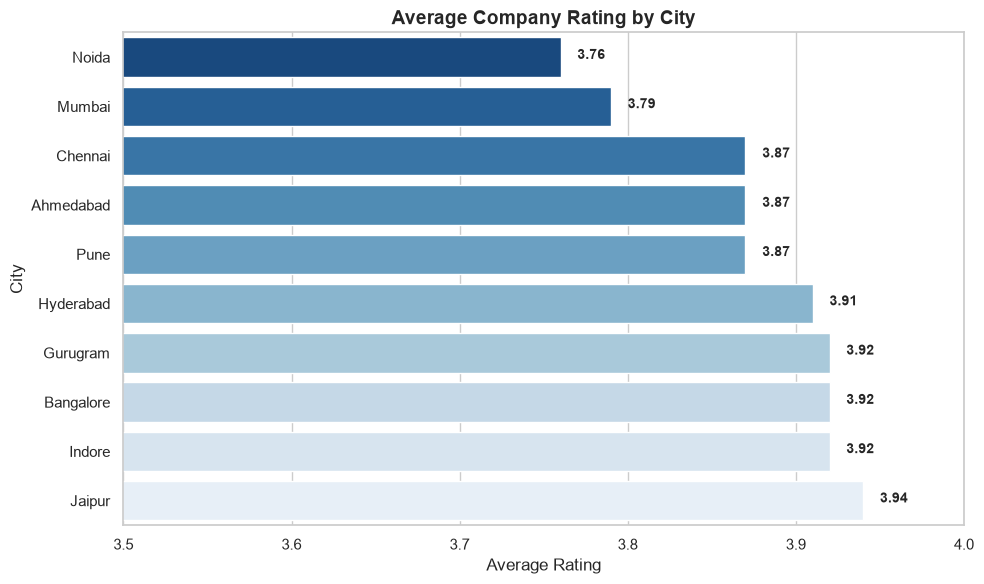

In [27]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sorted_ratings = city_ratings.sort_values(by='company_rating', ascending=True)

ax = sns.barplot(x='company_rating', y='city', data=sorted_ratings, palette='Blues_r')

plt.title('Average Company Rating by City', fontsize=14, fontweight='bold')
plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.xlim(3.5, 4.0) 

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.01, p.get_y() + p.get_height()/2.2, f'{width:.2f}', 
            ha='left', va='center', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

C:\Users\singh\AppData\Local\Temp\ipykernel_11432\3899490044.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='count', y='city', data=city_counts, palette='Purples_r')


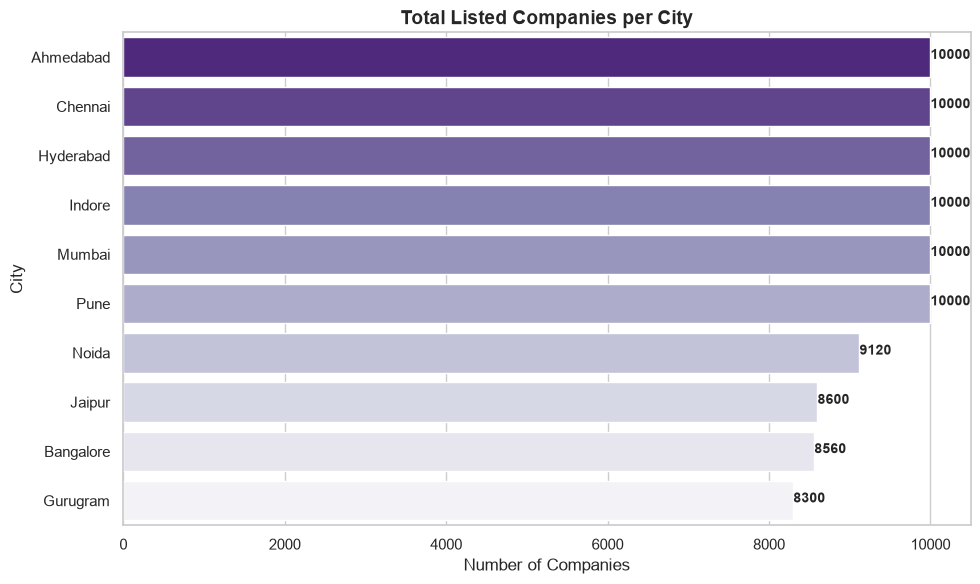

In [29]:
plt.figure(figsize=(10, 6))

city_counts = amt['city'].value_counts().reset_index()
city_counts.columns = ['city', 'count']

ax = sns.barplot(x='count', y='city', data=city_counts, palette='Purples_r')

plt.title('Total Listed Companies per City', fontsize=14, fontweight='bold')
plt.xlabel('Number of Companies', fontsize=12)
plt.ylabel('City', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 1, p.get_y() + p.get_height()/2.2, int(width), 
            ha='left', va='center', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [31]:
sns.set_theme(style="whitegrid")

amt['other_data'] = amt['other_data'].fillna('')
split_data = amt['other_data'].str.split(',', expand=True)

amt['industry'] = split_data[0].str.strip() if len(split_data.columns) > 0 else 'Unknown'
amt['company_size'] = split_data[1].str.strip() if len(split_data.columns) > 1 else 'Unknown'

C:\Users\singh\AppData\Local\Temp\ipykernel_11432\1216934589.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_industries.values, y=top_industries.index, palette='crest')


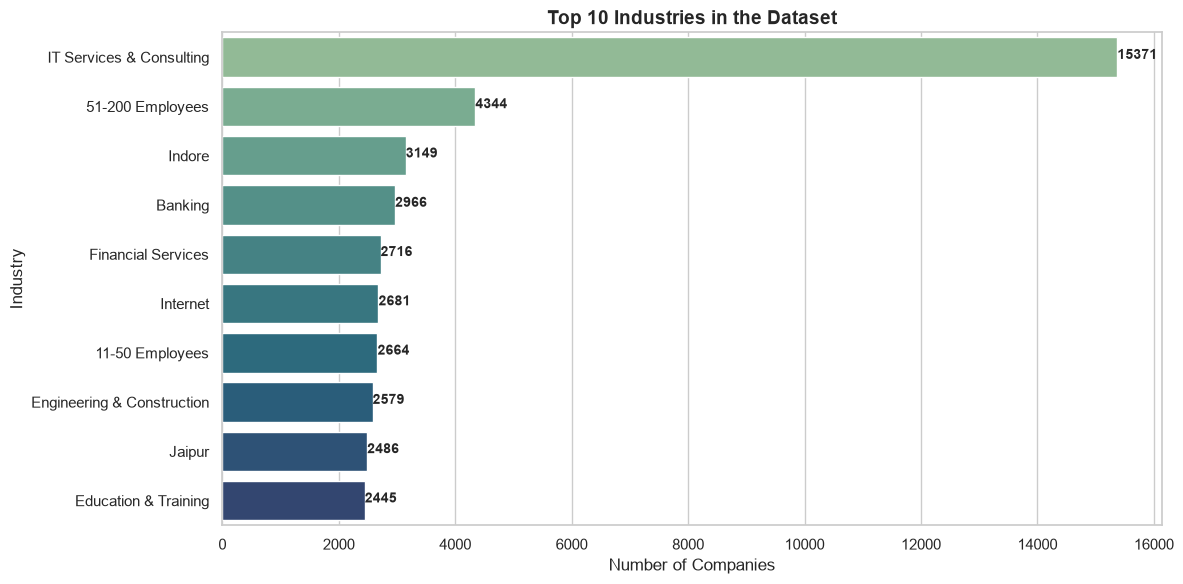

In [32]:
plt.figure(figsize=(12, 6))
top_industries = amt['industry'].value_counts().head(10)
ax = sns.barplot(x=top_industries.values, y=top_industries.index, palette='crest')
plt.title('Top 10 Industries in the Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Number of Companies', fontsize=12)
plt.ylabel('Industry', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 1, p.get_y() + p.get_height()/2.2, int(width), 
            ha='left', va='center', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

C:\Users\singh\AppData\Local\Temp\ipykernel_11432\772816282.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=size_counts.index, y=size_counts.values, palette='viridis')


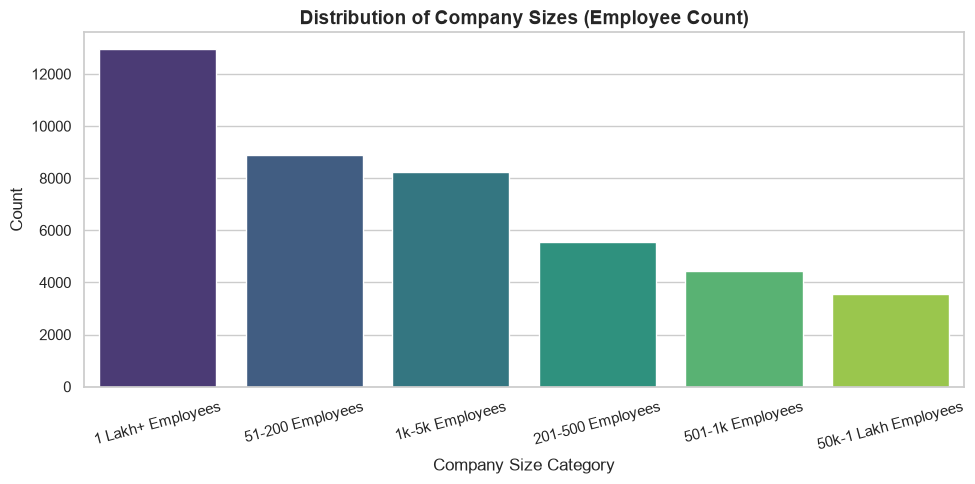

In [33]:
plt.figure(figsize=(10, 5))
size_counts = amt['company_size'].value_counts().head(6)
ax = sns.barplot(x=size_counts.index, y=size_counts.values, palette='viridis')
plt.title('Distribution of Company Sizes (Employee Count)', fontsize=14, fontweight='bold')
plt.xlabel('Company Size Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

C:\Users\singh\AppData\Local\Temp\ipykernel_11432\3074118579.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='city', y='company_rating', data=filtered_city_df, palette='Set2')


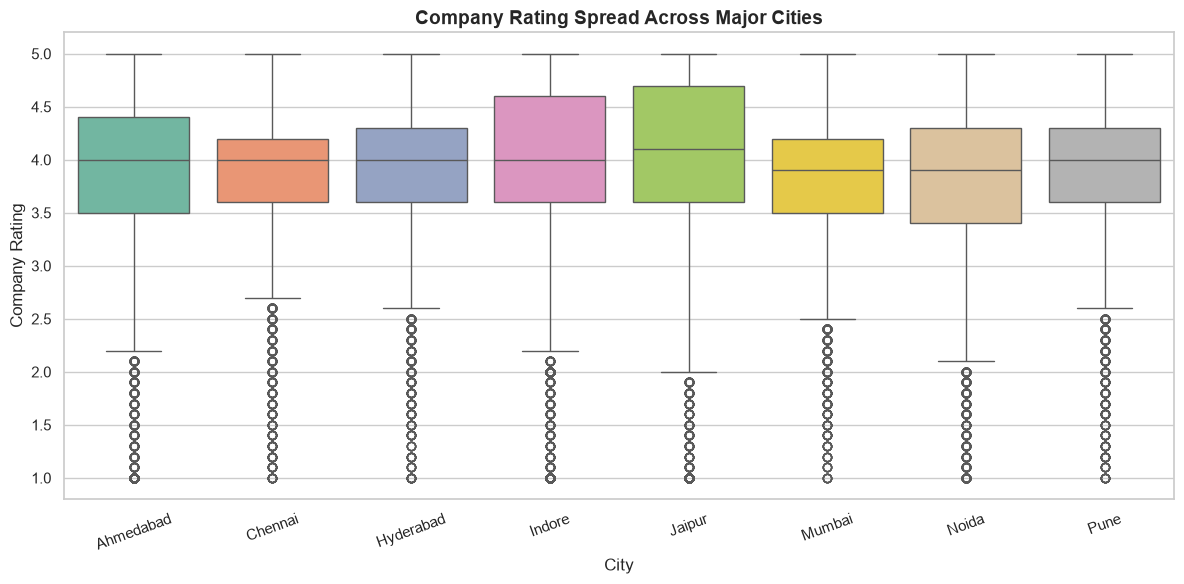

In [34]:
plt.figure(figsize=(12, 6))
top_cities = amt['city'].value_counts().head(8).index
filtered_city_df = amt[amt['city'].isin(top_cities)]

sns.boxplot(x='city', y='company_rating', data=filtered_city_df, palette='Set2')
plt.title('Company Rating Spread Across Major Cities', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Company Rating', fontsize=12)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [39]:
industry_stats = amt.groupby('industry').agg(
    avg_rating=('company_rating', 'mean'),
    total_companies=('company_name', 'count')
).reset_index()

top_industries = industry_stats[industry_stats['total_companies'] >= 5]
top_industries = top_industries.sort_values(by='avg_rating', ascending=False)

print("--- Top Rated Industries (Min 5 Companies) ---")
display(top_industries.head(10))

--- Top Rated Industries (Min 5 Companies) ---


,industry,avg_rating,total_companies
385,Jaipur +9 more,4.370000,10
35,28 years old,4.354545,22
54,44 years old,4.340000,5
387,Jodhpur +1 more,4.320000,5
527,Pune +10 more,4.320000,5
174,Chennai +11 more,4.311111,9
84,79 years old,4.300000,7
313,Indore +14 more,4.300000,5
244,Fortune India 500,4.300000,8
1,1 years old,4.260000,5


In [37]:
idx = amt.groupby('city')['company_rating'].idxmax()
top_per_city = amt.loc[idx, ['city', 'company_name', 'company_rating', 'industry']]
top_per_city = top_per_city.sort_values(by='company_rating', ascending=False)

print("--- Highest Rated Company in Each City ---")
display(top_per_city)

--- Highest Rated Company in Each City ---


,city,company_name,company_rating,industry
315,Ahmedabad,Taletel,5.0,Marketing & Advertising
18707,Chennai,Lavender Technology,5.0,IT Services & Consulting
76152,Noida,Acme Infolabs,5.0,IT Services & Consulting
37012,Hyderabad,Lavender Technology,5.0,IT Services & Consulting
47521,Indore,Qoulomb,5.0,Marketing & Advertising
57107,Jaipur,WeNet Global,5.0,IT Services & Consulting
85843,Pune,Perfecto Adecom,5.0,Marketing & Advertising
65619,Mumbai,Lavender Technology,5.0,IT Services & Consulting
10015,Bangalore,Amazon,4.1,Internet
28575,Gurugram,Amazon,4.1,Internet


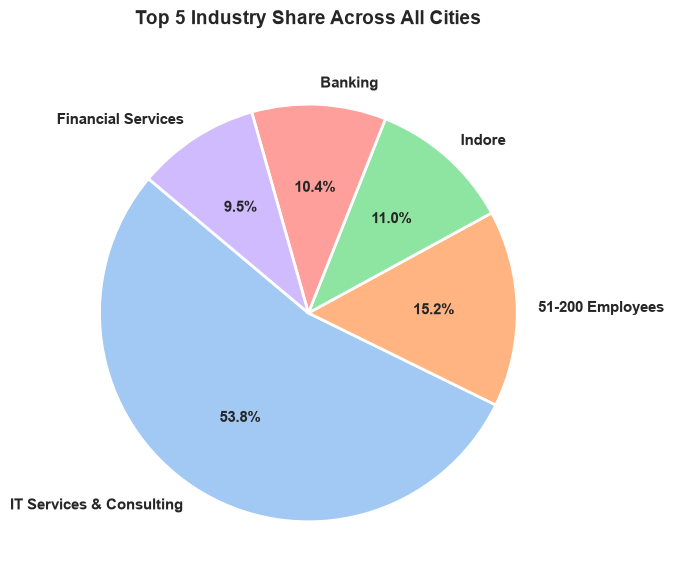

In [44]:
colors = sns.color_palette('pastel')[0:5]

plt.figure(figsize=(9, 6))
top_industries = amt['industry'].value_counts().head(5)

plt.pie(top_industries, labels=top_industries.index, colors=colors, autopct='%1.1f%%', 
        startangle=140, textprops={'fontsize': 11, 'fontweight': 'bold'}, 
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})

plt.title('Top 5 Industry Share Across All Cities', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

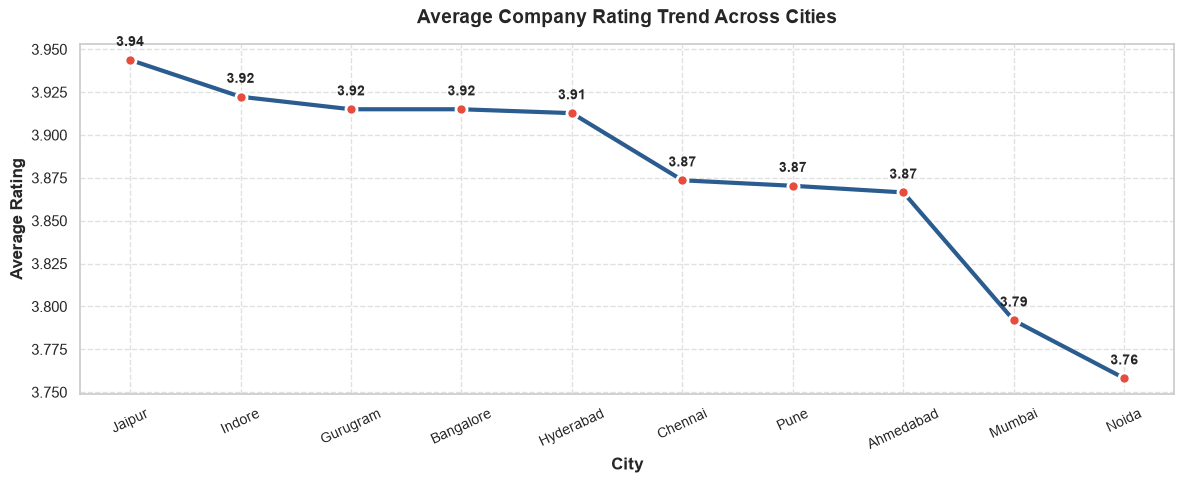

In [47]:
plt.figure(figsize=(12, 5))

city_avg = amt.groupby('city')['company_rating'].mean().reset_index()
city_avg = city_avg.sort_values(by='company_rating', ascending=False)

plt.plot(city_avg['city'], city_avg['company_rating'], marker='o', color='#2b5c8f', 
         linewidth=3, markersize=8, markerfacecolor='#e74c3c', markeredgecolor='white', markeredgewidth=2)

plt.title('Average Company Rating Trend Across Cities', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('City', fontsize=12, fontweight='semibold')
plt.ylabel('Average Rating', fontsize=12, fontweight='semibold')
plt.xticks(rotation=25, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

for i, txt in enumerate(city_avg['company_rating']):
    plt.annotate(f"{txt:.2f}", (city_avg['city'].iloc[i], city_avg['company_rating'].iloc[i]),
                 textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()